<a href="https://colab.research.google.com/github/etorrey-vc/Ken-and-Friends-CMPU-250-/blob/main/CMPU250_EDA_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Run for data import/data cleaning

In [ ]:
# @title
import pandas as pd
import numpy as np


## ***Data cleaning***


speed_dating_df = pd.read_csv('csv_result-speeddating.csv')
speed_dating_df_copy = speed_dating_df.copy()
# Got the column names of those that had the bracket values
d_columns= speed_dating_df.loc[:, speed_dating_df.columns.str.startswith('d_')].iloc[:, 1:].columns
speed_dating_df = speed_dating_df.drop(columns=d_columns)
# Columns of partner preferences --> dropping them because we will just like from the perspective of one student
pref_o_columns = speed_dating_df.loc[:, speed_dating_df.columns.str.startswith('pref_o')].columns
# Drop these columns
speed_dating_df = speed_dating_df.drop(columns=pref_o_columns)
speed_dating_df = speed_dating_df.drop(columns=['decision_o', 'expected_happy_with_sd_people', 'age'])
# Drop columns about hobby we will just use the interest correlations columns
hobby_columns = speed_dating_df.iloc[:, 36:52].columns
speed_dating_df = speed_dating_df.drop(columns=hobby_columns)
# Drop columns about partners evalution --> again we will only look from one perspective
partner_eval_columns = speed_dating_df.loc[:, speed_dating_df.columns.str.endswith('_o')].iloc[:, 2:]
speed_dating_df = speed_dating_df.drop(columns=partner_eval_columns)
# Drop columns about thoughts of self, not necessary
speed_dating_df = speed_dating_df.drop(columns=['id', 'wave', 'attractive','sincere', 'intelligence', 'funny', 'ambition', 'met', 'match', 'expected_num_interested_in_me','expected_num_matches', 'guess_prob_liked', 'sports', 'has_null'])
# Drop all rows in demographics category that have null values
null_race_rows = speed_dating_df[speed_dating_df['race'] == '?'].index
speed_dating_df = speed_dating_df.drop(null_race_rows)
null_age_o_rows = speed_dating_df[speed_dating_df['age_o'] == '?'].index
speed_dating_df = speed_dating_df.drop(null_age_o_rows)

speed_dating_df['age_o'] = speed_dating_df['age_o'].astype(int)

# Changing all preference values to floats while dropping those with null
preference_cols = speed_dating_df.loc[:, speed_dating_df.columns.str.contains('important', case=False)].columns
for preference in preference_cols:
    null_index = speed_dating_df[speed_dating_df[preference] == '?'].index
    speed_dating_df = speed_dating_df.drop(null_index)

for preference in preference_cols:
    speed_dating_df[preference] = speed_dating_df[preference].astype(float)

# Changing all evaluation values to floats while dropping those with null
eval_of_partner_cols = speed_dating_df.loc[:, speed_dating_df.columns.str.contains('partner', case=False)].columns
for rating in eval_of_partner_cols:
    null_index = speed_dating_df[speed_dating_df[rating] == '?'].index
    speed_dating_df = speed_dating_df.drop(null_index)

for rating in eval_of_partner_cols:
    speed_dating_df[rating] = speed_dating_df[rating].astype(float)

# Changing all miscellaneous values to floats while dropping those with null

misc_cols = ['importance_same_race', 'importance_same_religion', 'interests_correlate', 'like']
for misc in misc_cols:
    null_index = speed_dating_df[speed_dating_df[misc] == '?'].index
    speed_dating_df = speed_dating_df.drop(null_index)

for misc in misc_cols:
    speed_dating_df[misc] = speed_dating_df[misc].astype(float)

/tmp/ipykernel_2408/653623619.py:9: DtypeWarning: Columns (4,11,12,16,17,18,19,20,40,41,42,43,44,45,52,53,54,55,56,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,108,110) have mixed types. Specify dtype option on import or set low_memory=False.
  speed_dating_df = pd.read_csv('csv_result-speeddating.csv')


In [ ]:
# Table of summary statistics
table_of_summary_statistics = speed_dating_df.describe()

In [ ]:
# Too many columns that the full dataset is not shown so split up into two for easier visualization
speed_dating_df1 = speed_dating_df.iloc[:, :14]
speed_dating_df2 = speed_dating_df.iloc[:, 14:]

In [ ]:
importance_cols = ['attractive_important', 'sincere_important', 'intellicence_important',"funny_important",'ambtition_important', 'shared_interests_important']

gender_average = speed_dating_df.groupby('gender')[importance_cols].mean()

gender_average

,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important
gender,,,,,,
female,17.961035,18.331765,20.918247,17.305845,12.943969,12.479689
male,26.481166,16.532820,19.760495,17.538638,8.716406,11.084522


In [ ]:
race_colors = {
    'Asian/Pacific Islander/Asian-American': '#E69F00',
    'Black/African American': '#56B4E9',
    'European/Caucasian-American': '#009E73',
    'Latino/Hispanic American': '#F0E442',
    'Other': '#0072B2'
}

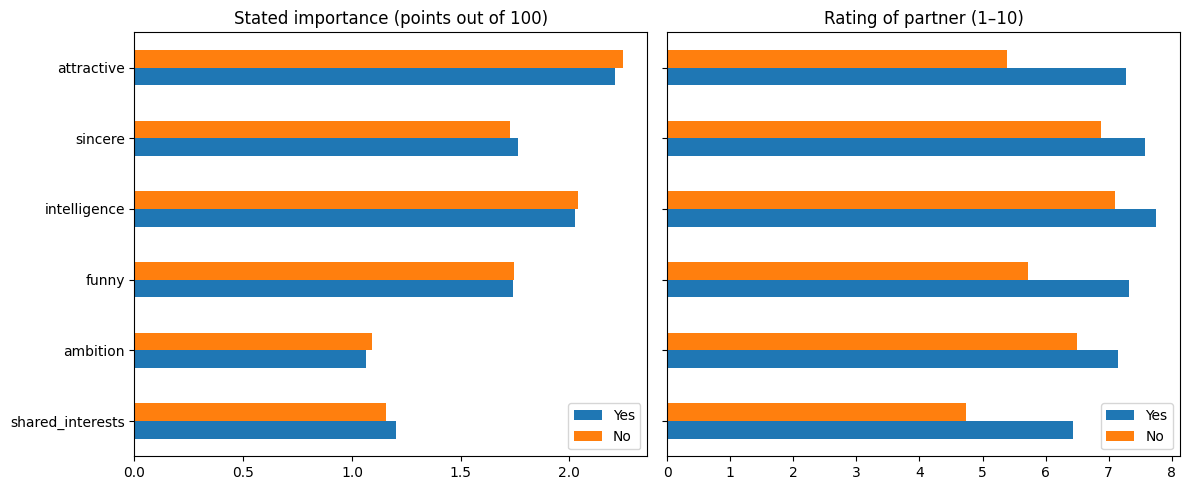

In [ ]:
import matplotlib.pyplot as plt

traits = ['attractive', 'sincere', 'intelligence', 'funny', 'ambition', 'shared_interests']
imp_cols = ['attractive_important', 'sincere_important', 'intellicence_important',
            'funny_important', 'ambtition_important', 'shared_interests_important']
eval_cols = ['attractive_partner', 'sincere_partner', 'intelligence_partner',
             'funny_partner', 'ambition_partner', 'shared_interests_partner']

imp = pd.DataFrame({'Yes': pref_eval_dec_yes_mean[imp_cols].values,
                    'No': pref_eval_dec_no_mean[imp_cols].values}, index=traits)
ev = pd.DataFrame({'Yes': pref_eval_dec_yes_mean[eval_cols].values,
                   'No': pref_eval_dec_no_mean[eval_cols].values}, index=traits)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
imp[::-1].plot.barh(ax=axes[0], title='Stated importance (points out of 100)')
ev[::-1].plot.barh(ax=axes[1], title='Rating of partner (1–10)')
plt.tight_layout()

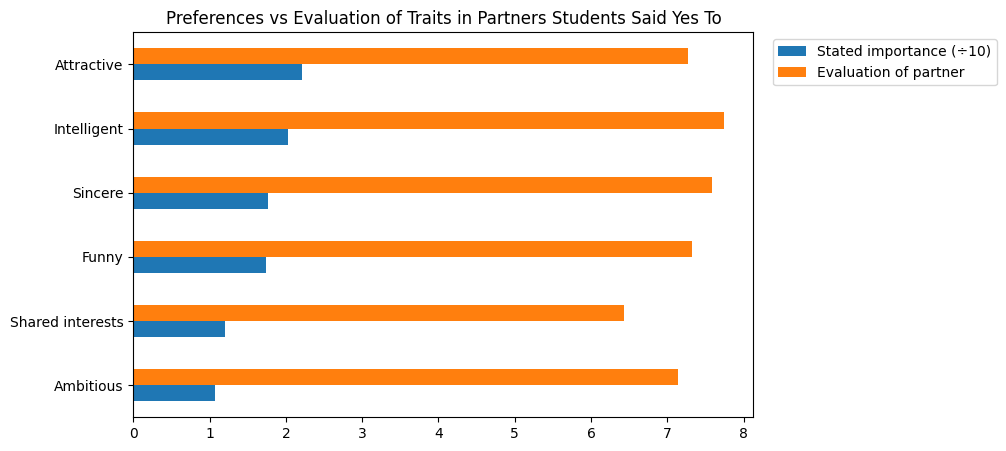

In [ ]:
speed_dating_df.columns
pref_eval_dec_cols = [
       'attractive_important', 'sincere_important', 'intellicence_important',
       'funny_important', 'ambtition_important', 'shared_interests_important',
       'attractive_partner', 'sincere_partner', 'intelligence_partner',
       'funny_partner', 'ambition_partner', 'shared_interests_partner', 'decision']

pref_eval_dec_df = speed_dating_df[pref_eval_dec_cols]
pref_eval_dec_yes = pref_eval_dec_df[pref_eval_dec_df['decision'] == 1].drop(columns='decision')
pref_eval_dec_yes[['attractive_important', 'sincere_important', 'intellicence_important',
       'funny_important', 'ambtition_important', 'shared_interests_important']] = pref_eval_dec_yes[['attractive_important', 'sincere_important', 'intellicence_important',
       'funny_important', 'ambtition_important', 'shared_interests_important']] / 10
reordered = ['attractive_important', 'attractive_partner', 'sincere_important', 'sincere_partner', 'intellicence_important', 'intelligence_partner', 'funny_important', 'funny_partner', 'ambtition_important', 'ambition_partner', 'shared_interests_important','shared_interests_partner']
pref_eval_dec_yes = pref_eval_dec_yes[reordered]
pref_eval_dec_yes_mean = pref_eval_dec_yes.mean()
pref_eval_dec_yes_mean
traits = ['Attractive', 'Sincere', 'Intelligent', 'Funny', 'Ambitious', 'Shared interests']
imp_cols = ['attractive_important', 'sincere_important', 'intellicence_important',
            'funny_important', 'ambtition_important', 'shared_interests_important']
eval_cols = ['attractive_partner', 'sincere_partner', 'intelligence_partner',
             'funny_partner', 'ambition_partner', 'shared_interests_partner']

grouped = pd.DataFrame({
    'Stated importance (÷10)': pref_eval_dec_yes_mean[imp_cols].values,
    'Evaluation of partner': pref_eval_dec_yes_mean[eval_cols].values,
}, index=traits)

grouped.sort_values('Stated importance (÷10)').plot.barh(figsize=(8, 5), title='Preferences vs Evaluation of Traits in Partners Students Said Yes To')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

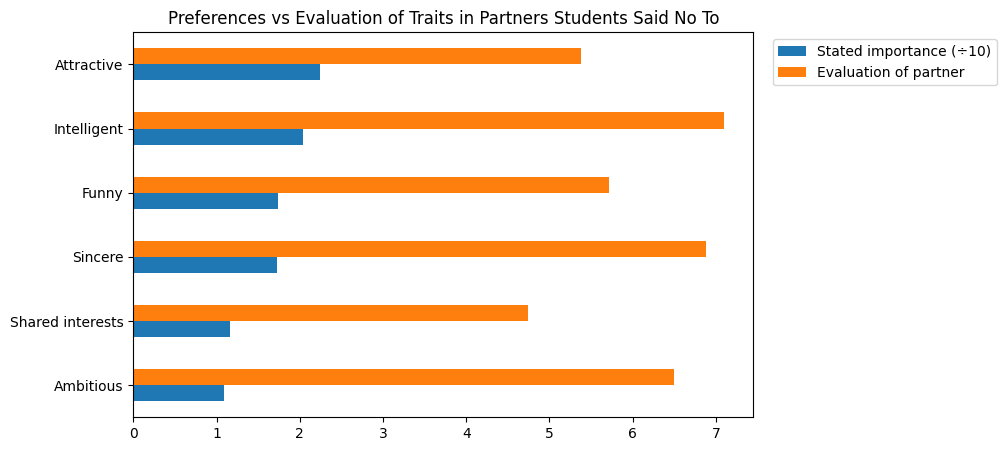

In [ ]:
pref_eval_dec_no = pref_eval_dec_df[pref_eval_dec_df['decision'] == 0].drop(columns='decision')
pref_eval_dec_no[imp_cols] = pref_eval_dec_no[imp_cols] / 10
pref_eval_dec_no_mean = pref_eval_dec_no.mean()

grouped_no = pd.DataFrame({
    'Stated importance (÷10)': pref_eval_dec_no_mean[imp_cols].values,
    'Evaluation of partner': pref_eval_dec_no_mean[eval_cols].values,
}, index=traits)

grouped_no.sort_values('Stated importance (÷10)').plot.barh(figsize=(8, 5), title='Preferences vs Evaluation of Traits in Partners Students Said No To')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

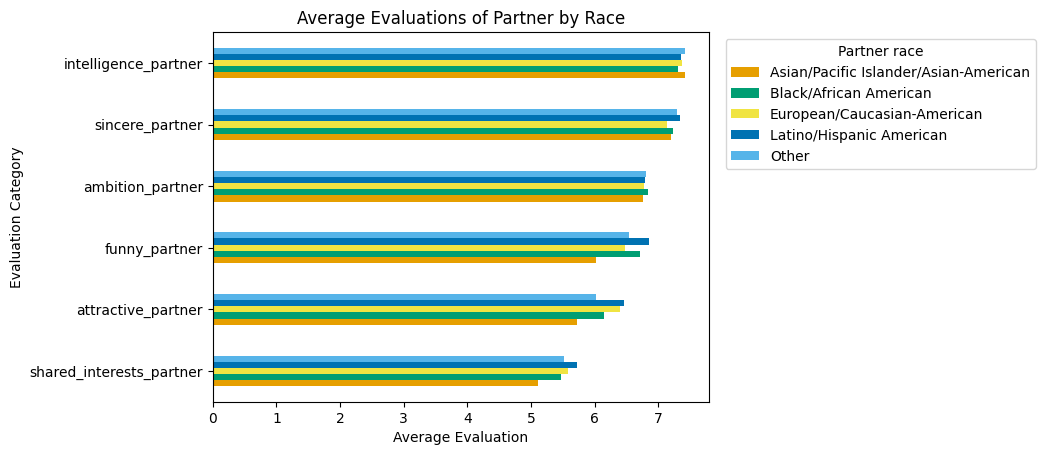

In [ ]:
eval_by_race = speed_dating_df.groupby('race_o').mean(numeric_only=True)[['attractive_partner', 'sincere_partner',
       'intelligence_partner', 'funny_partner', 'ambition_partner',
       'shared_interests_partner']]

order = eval_by_race.mean().sort_values().index

eval_by_race[order].T.plot.barh(color=['#E69F00', '#009E73','#F0E442','#0072B2','#56B4E9'], title='Average Evaluations of Partner by Race', xlabel='Average Evaluation', ylabel='Evaluation Category')
plt.legend(title='Partner race', bbox_to_anchor=(1.02, 1), loc='upper left')

In [ ]:
eval_by_race.idxmax()
eval_by_race.idxmin()
eval_by_race.style.highlight_max(axis=0, color='lightgreen').highlight_min(axis=0, color='pink')



,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner
race_o,,,,,,
Asian/Pacific Islander/Asian-American,5.715543,7.204614,7.412568,6.014876,6.758349,5.115361
Black/African American,6.140845,7.222535,7.304225,6.712676,6.836620,5.467606
European/Caucasian-American,6.398899,7.130047,7.365889,6.468799,6.773597,5.586786
Latino/Hispanic American,6.453971,7.334838,7.354693,6.855596,6.786101,5.716606
Other,6.020225,7.298876,7.420225,6.539326,6.811236,5.522472


<Axes: title={'center': 'Summed Average Evaluations by Race'}, xlabel='Total Evaluation', ylabel='Races'>

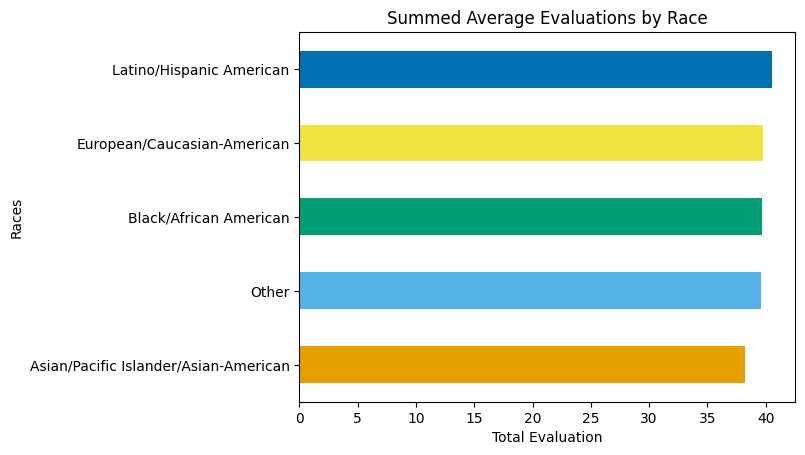

In [ ]:
total_eval_values = []
race_cols = speed_dating_df['race_o'].unique()
for i in range(len(eval_by_race)):
    total_eval_values.append(eval_by_race.iloc[i].sum())

total_eval_values = eval_by_race.sum(axis=1)
total_eval_values.sort_values().plot.barh(color=['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2'], title='Summed Average Evaluations by Race', xlabel='Total Evaluation', ylabel='Races')

<Axes: title={'center': 'Student Size by Race'}, xlabel='Total Students', ylabel='Races'>

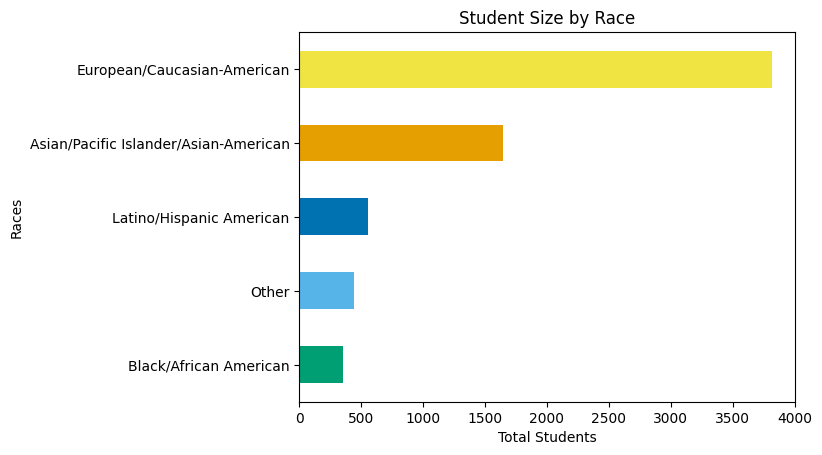

In [ ]:
speed_dating_df.groupby('race_o').size().sort_values().plot.barh(color=['#009E73', '#56B4E9', '#0072B2','#E69F00','#F0E442'], title='Student Size by Race', xlabel='Total Students', ylabel='Races')

<Axes: title={'center': 'Decision Percentages by Partner Race'}, xlabel='Decision Percent', ylabel='Race'>

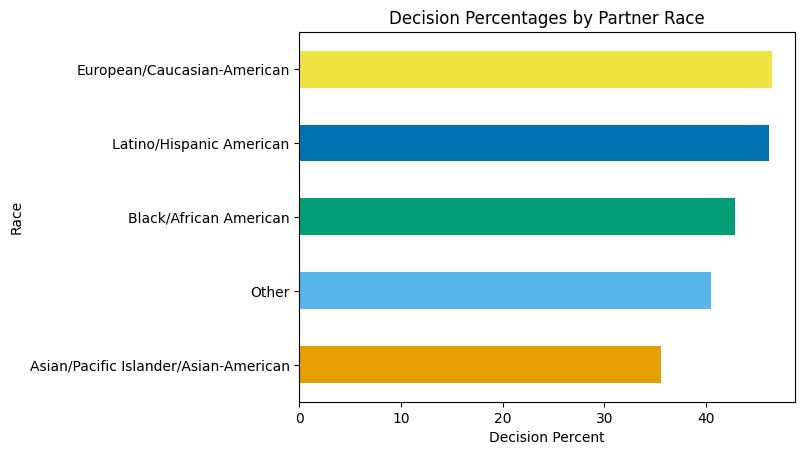

In [ ]:
mean_dec_by_race = speed_dating_df.groupby('race_o')['decision'].mean().sort_values().apply(lambda x : x * 100)
mean_dec_by_race.plot.barh(color=['#E69F00','#56B4E9','#009E73', '#0072B2', '#F0E442'], title='Decision Percentages by Partner Race', xlabel='Decision Percent', ylabel='Race')